# 中心与分布优势组合

## tl;dr
50:50 在相同的 515 个历史站日上实现 RMSE −0.380%、CRPS −0.280%、NLL −0.210%。三项区间仍跨零，前半窗 NLL 略差；研究候选，生产不动。

## Context & Methods
固定 25/50/75% 组合、三指标联合目标、训练不劣约束；50:50 为计算前指定主要组合。逐时点训练只使用已知标签。

### Key Assumptions
已查看历史上的探索性追加；不是独立盲测。33 个非 ASOS 站；概率指标仅是后处理前线性池；总体改善不是每站改善。

In [1]:
import json, hashlib, sys
from pathlib import Path
base=Path.cwd();sys.path.insert(0,str(base))
import joint as J
guard=J.C.study.Guard()
r=json.loads((base/'results.json').read_text())
rows=json.loads((base/'scores.json').read_text())
for name,sha in r['inputs_sha256'].items():
    assert hashlib.sha256((J.C.ROOT/name).read_bytes()).hexdigest()==sha
assert len(rows)==515
print('515 paired station-days; 33 stations; 23 dates')

515 paired station-days; 33 stations; 23 dates


## Data
输入与上一轮相同，全部三指标统一用具有恢复分布的 515 条；上轮 RMSE 的 604 条不用于本表。

In [2]:
v=json.loads((base/'validation.json').read_text())
for key in ['jensen_checks','cdf_check_n','cdf_max_error','joint_gradient_max_error','target_label_mutation_invariant','zero_hit_n']:
    print(key, v[key])

jensen_checks 4635
cdf_check_n 4120
cdf_max_error 1.7763568394002505e-15
joint_gradient_max_error 1.6340323538699408e-10
target_label_mutation_invariant True
zero_hit_n 0


## Results
比较基线为现行权重。百分比小于零为改善。

In [3]:
labels={'current': 'Current', 'center_stack21': 'Center + ridge', 'crps_hier21': 'Hierarchical CRPS', 'blend50': '50:50 blend', 'joint': 'Joint objective', 'joint_guarded': 'Joint + training guards'}
print(f"{'Candidate':26} {'RMSE':>10} {'CRPS':>10} {'NLL':>10}")
for arm,label in labels.items():
    m=J.metrics(rows,arm)
    for metric in ['rmse','crps','nll']:assert abs(m[metric]-r['arms'][arm][metric])<1e-12
    print(f"{label:26} {m['rmse']:10.6f} {m['crps']:10.6f} {m['nll']:10.6f}")

Candidate                        RMSE       CRPS        NLL
Current                      1.283902   0.662243   1.584997
Center + ridge               1.276113   0.660667   1.584723
Hierarchical CRPS            1.284625   0.661270   1.579986
50:50 blend                  1.279026   0.660390   1.581672
Joint objective              1.286780   0.662233   1.578242
Joint + training guards      1.286815   0.661740   1.577170


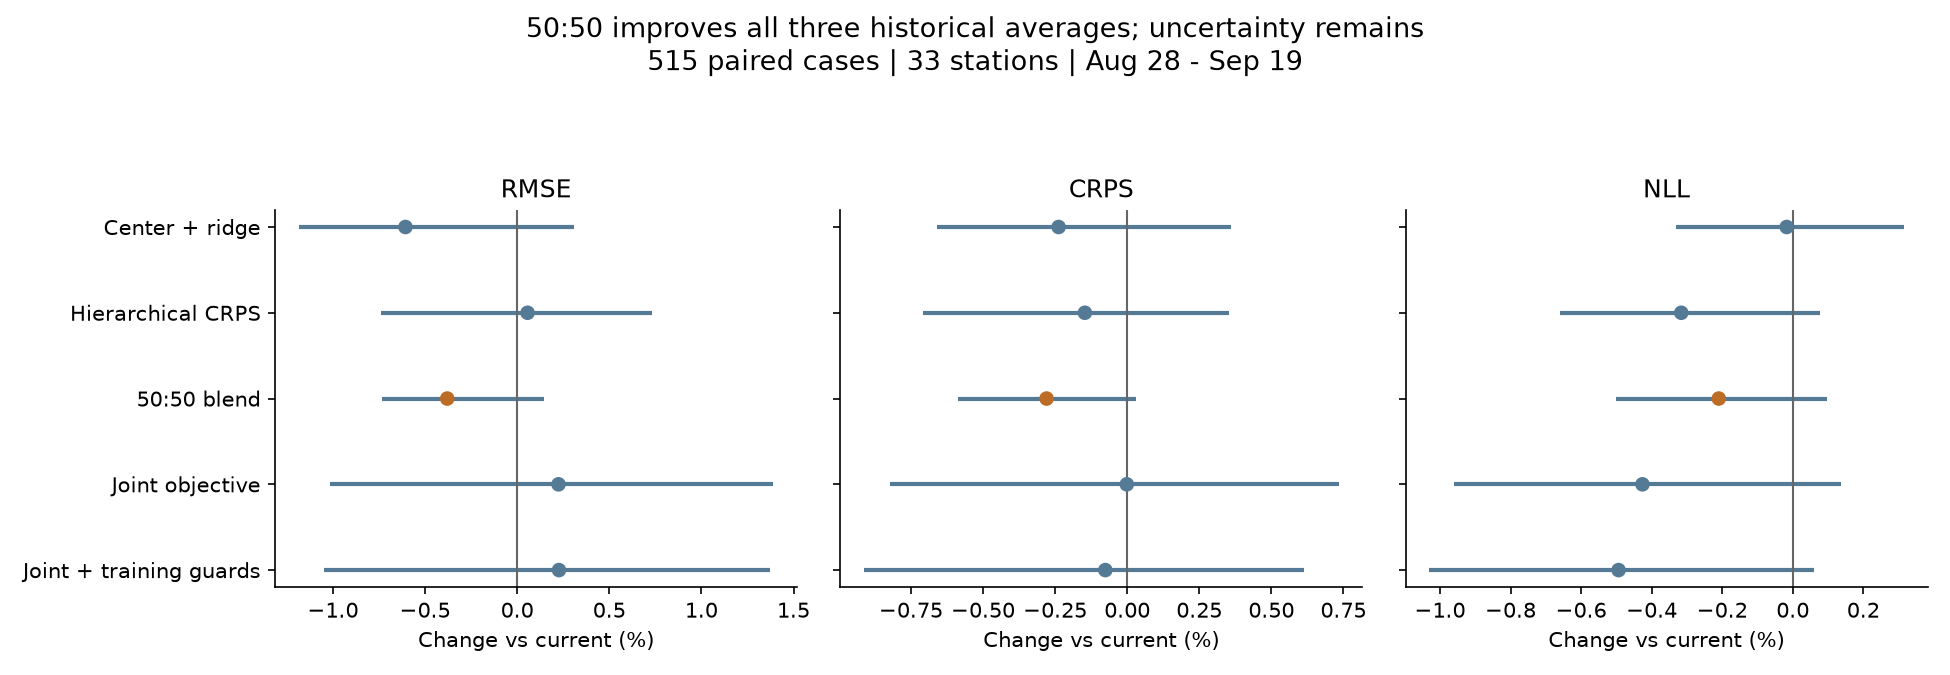

In [4]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display, Image
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
arms=[a for a in labels if a!='current']; y=np.arange(len(arms))
fig,axes=plt.subplots(1,3,figsize=(13,4.5),sharey=True)
for ax,metric in zip(axes,['rmse','crps','nll']):
    d=np.array([r['arms'][a]['change_pct'][metric] for a in arms])
    ci=np.array([r['arms'][a]['delta_ci95'][metric] for a in arms])*100/r['arms']['current'][metric]
    ax.hlines(y,ci[:,0],ci[:,1],color='#557A95',linewidth=2)
    ax.scatter(d,y,color=['#557A95','#557A95','#BC6C25','#557A95','#557A95'],zorder=3)
    ax.axvline(0,color='#666',linewidth=1);ax.set_title(metric.upper());ax.set_xlabel('Change vs current (%)')
axes[0].set_yticks(y,[labels[a] for a in arms]);axes[0].invert_yaxis()
fig.suptitle('50:50 improves all three historical averages; uncertainty remains\n515 paired cases | 33 stations | Aug 28 - Sep 19',fontsize=13)
fig.tight_layout(rect=(0,0,1,.90));fig.savefig(base/'joint_comparison.png',dpi=150);plt.close(fig)
display(Image(filename=str(base/'joint_comparison.png')))

三日块 bootstrap 的三项区间均跨零。50:50 的均值改善，不能解读成已证明未来三降。

In [5]:
b=r['arms']['current'];m=r['arms']['blend50']
for half,x in m['halves'].items():
    print(half,{k:round(100*(x[k]/b['halves'][half][k]-1),4) for k in ['rmse','crps','nll']})
print('Stations with all three lower:', m['station_all_three_lower_n'],'/33')
print('Leave-one-station-out ranges:',m['leave_one_station_out_delta_range'])

first {'rmse': -0.8165, 'crps': -0.3845, 'nll': 0.0266}
second {'rmse': -0.022, 'crps': -0.2067, 'nll': -0.3607}
Stations with all three lower: 11 /33
Leave-one-station-out ranges: {'crps': [-0.0025542946948949874, -0.001149249011211495], 'nll': [-0.004225827465172305, -0.0017217318371782753], 'rmse': [-0.0062073047043458285, -0.00315896994484266]}


## Takeaways
保留 50:50 为下一主要候选。冻结比例，复现完整服务链并使用未参与本轮设计的历史外层验证；未来观察只验证接口/到达，不算 OOS。来源与限制见 REPORT.md / PROTOCOL.md；本目录脚本可重算，manifest 记录哈希。